# Proyecto: Simulación de Inundación

## Sección 1: Modelado del Terreno (Asignado a: Integrante 1)

In [16]:
import numpy as np

class TerrenoSimulacion:
    def __init__(self, filas=10, columnas=10):
        """
        Inicializa la cuadrícula del terreno.
        Convenciones de valores en la matriz:
          0  -> Terreno libre / seguro (Costo estándar)
         1-3 -> Niveles de riesgo por inundación (1 = Bajo, 2 = Medio, 3 = Alto)
         -1  -> Zona bloqueada / intransitable (Muros o inundación crítica)
        """
        self.filas = filas
        self.columnas = columnas
        self.matriz = np.zeros((filas, columnas), dtype=int)

        # Coordenadas por defecto para el punto de inicio y el refugio
        self.inicio = (0, 0)
        self.refugio = (filas - 1, columnas - 1)

    def configurar_escenario_base(self):
        """Configura un mapa de prueba predeterminado con obstáculos y zonas de riesgo."""
        # Establecemos zonas bloqueadas (-1) simulando desbordamientos impenetrables
        self.matriz[2, 1:6] = -1
        self.matriz[5, 3:9] = -1

        # Establecemos diferentes niveles de riesgo de inundación (1, 2, 3)
        self.matriz[1, :] = 1        # Riesgo bajo en toda la fila 1
        self.matriz[3, 0:4] = 2      # Riesgo medio
        self.matriz[4, 4:] = 3       # Riesgo alto
        self.matriz[6:8, 2] = 2      # Zona lateral con riesgo medio

        # Asegurar que inicio y refugio estén libres de obstáculos
        self.matriz[self.inicio] = 0
        self.matriz[self.refugio] = 0

    def obtener_costo_celda(self, celda, costo_base=1):
        """
        Calcula el costo de transitar por una celda considerando su nivel de riesgo.
        Si la celda está bloqueada (-1) o fuera de límites, retorna infinito.
        """
        f, c = celda

        # Validar límites de la cuadrícula
        if not (0 <= f < self.filas and 0 <= c < self.columnas):
            return float('inf')

        nivel_riesgo = self.matriz[f, c]

        # Si la zona está completamente bloqueada
        if nivel_riesgo == -1:
            return float('inf')

        # Fórmula de costo ponderado:
        # Costo Base + (Nivel de Riesgo * Factor de penalización por riesgo)
        factor_penalizacion = 3
        costo_total = costo_base + (nivel_riesgo * factor_penalizacion)

        return costo_total

    def mostrar_mapa(self):
        """Muestra una representación textual clara de la matriz en consola."""
        print("Leyenda: [ 0 ] Libre | [ 1-3 ] Riesgo de Inundación | [ -1 ] Bloqueado\n")
        print(self.matriz)

# --- PRUEBA LOCAL DEL MÓDULO ---
if __name__ == "__main__":
    # Crear terreno de 10x10
    terreno = TerrenoSimulacion(10, 10)
    terreno.configurar_escenario_base()
    terreno.mostrar_mapa()

    # Probar costos de ejemplo
    print("\nPrueba de costos:")
    print(f"Costo celda libre (0,0): {terreno.obtener_costo_celda((0, 0))}")
    print(f"Costo celda con riesgo (1,5): {terreno.obtener_costo_celda((1, 5))}")
    print(f"Costo celda bloqueada (2,2): {terreno.obtener_costo_celda((2, 2))}")

Leyenda: [ 0 ] Libre | [ 1-3 ] Riesgo de Inundación | [ -1 ] Bloqueado

[[ 0  0  0  0  0  0  0  0  0  0]
 [ 1  1  1  1  1  1  1  1  1  1]
 [ 0 -1 -1 -1 -1 -1  0  0  0  0]
 [ 2  2  2  2  0  0  0  0  0  0]
 [ 0  0  0  0  3  3  3  3  3  3]
 [ 0  0  0 -1 -1 -1 -1 -1 -1  0]
 [ 0  0  2  0  0  0  0  0  0  0]
 [ 0  0  2  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0]
 [ 0  0  0  0  0  0  0  0  0  0]]

Prueba de costos:
Costo celda libre (0,0): 1
Costo celda con riesgo (1,5): 4
Costo celda bloqueada (2,2): inf


## Sección 2: Dijkstra Adaptado (Asignado a: Integrante 2)

In [17]:
import heapq

class DijkstraEvacuacion:
    def __init__(self, terreno):
        """
        Inicializa el algoritmo de Dijkstra adaptado para la simulación de evacuación.
        Recibe una instancia de TerrenoSimulacion.
        """
        self.terreno = terreno

    def obtener_vecinos(self, celda):
        """
        Retorna las celdas vecinas válidas (arriba, abajo, izquierda, derecha).
        """
        f, c = celda
        movimientos = [(-1, 0), (1, 0), (0, -1), (0, 1)]
        vecinos = []

        for df, dc in movimientos:
            nf, nc = f + df, c + dc
            if 0 <= nf < self.terreno.filas and 0 <= nc < self.terreno.columnas:
                if self.terreno.matriz[nf, nc] != -1:
                    vecinos.append((nf, nc))

        return vecinos

    def buscar_ruta(self):
        """
        Ejecuta el algoritmo de Dijkstra para encontrar la ruta óptima
        desde self.terreno.inicio hasta self.terreno.refugio,
        minimizando el costo acumulado por riesgo de inundación.
        """
        inicio = self.terreno.inicio
        refugio = self.terreno.refugio

        pq = [(0, inicio)]
        costos_minimos = {inicio: 0}
        camino_previo = {inicio: None}

        while pq:
            costo_actual, celda_actual = heapq.heappop(pq)

            if celda_actual == refugio:
                break

            if costo_actual > costos_minimos.get(celda_actual, float('inf')):
                continue

            for vecino in self.obtener_vecinos(celda_actual):
                costo_movimiento = self.terreno.obtener_costo_celda(vecino)

                if costo_movimiento == float('inf'):
                    continue

                nuevo_costo = costo_actual + costo_movimiento

                if nuevo_costo < costos_minimos.get(vecino, float('inf')):
                    costos_minimos[vecino] = nuevo_costo
                    camino_previo[vecino] = celda_actual
                    heapq.heappush(pq, (nuevo_costo, vecino))

        ruta = []
        actual = refugio

        if actual not in camino_previo and actual != inicio:
            return None, float('inf')

        while actual is not None:
            ruta.append(actual)
            actual = camino_previo.get(actual)

        ruta.reverse()
        return ruta, costos_minimos.get(refugio, float('inf'))

# --- PRUEBA LOCAL DE LA SECCIÓN 2 ---
if __name__ == "__main__":
    terreno_prueba = TerrenoSimulacion(10, 10)
    terreno_prueba.configurar_escenario_base()

    dijkstra = DijkstraEvacuacion(terreno_prueba)
    ruta_optima, costo_total = dijkstra.buscar_ruta()

    print("\nResultado de Dijkstra Adaptado:")
    print(f"Costo total de evacuación: {costo_total}")
    print(f"Ruta óptima encontrada: {ruta_optima}")


Resultado de Dijkstra Adaptado:
Costo total de evacuación: 27
Ruta óptima encontrada: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (4, 1), (5, 1), (6, 1), (7, 1), (8, 1), (8, 2), (8, 3), (8, 4), (8, 5), (8, 6), (8, 7), (8, 8), (8, 9), (9, 9)]


## Sección 3: A* con Riesgo (Asignado a: Integrante 3)

In [18]:
import heapq
import itertools
import time


class AEstrellaEvacuacion(DijkstraEvacuacion):
    def __init__(self, terreno):
        """
        A* adaptado para la simulación de evacuación.
        Recibe una instancia de TerrenoSimulacion.

        Después de buscar_ruta() quedan disponibles estas métricas:
          self.nodos_expandidos -> trabajo realizado (celdas sacadas de la frontera)
          self.nodos_generados  -> celdas agregadas a la frontera
          self.frontera_max     -> tamaño máximo de la frontera (memoria)
          self.explorados       -> lista de celdas expandidas, en orden (Sección 4)
          self.tiempo_ms        -> tiempo real de ejecución
        """
        super().__init__(terreno)
        self.nodos_expandidos = 0
        self.nodos_generados = 0
        self.frontera_max = 0
        self.explorados = []
        self.tiempo_ms = 0.0

    def heuristica(self, celda):
        """
        Distancia Manhattan hasta el refugio.

        Es ADMISIBLE (nunca sobreestima el costo real) porque:
          - En 4 direcciones se necesitan al menos |df| + |dc| pasos para llegar.
          - Cada paso cuesta como mínimo 1 (costo_base); el riesgo solo suma.
        Por eso A* encuentra la misma ruta de menor costo que Dijkstra,
        pero explora menos celdas porque "apunta" hacia el refugio.
        """
        f, c = celda
        fr, cr = self.terreno.refugio
        return abs(f - fr) + abs(c - cr)

    def buscar_ruta(self):
        """
        Ejecuta A* desde self.terreno.inicio hasta self.terreno.refugio.
        Prioridad de cada celda: f(n) = g(n) + h(n)
          g(n): costo real acumulado desde el inicio (distancia + riesgo)
          h(n): estimación del costo restante (heurística)

        Retorna (ruta, costo), con el mismo formato que DijkstraEvacuacion:
          ruta  -> lista de (fila, col), o None si el refugio es inaccesible
          costo -> costo total de la ruta, o inf si no hay ruta
        """
        t0 = time.perf_counter()
        inicio = self.terreno.inicio
        refugio = self.terreno.refugio

        self.nodos_expandidos = 0
        self.nodos_generados = 0
        self.frontera_max = 0
        self.explorados = []

        # Si el inicio o el refugio están bloqueados, no hay nada que buscar
        if (self.terreno.obtener_costo_celda(inicio) == float('inf') or
                self.terreno.obtener_costo_celda(refugio) == float('inf')):
            self.tiempo_ms = (time.perf_counter() - t0) * 1000
            return None, float('inf')

        desempate = itertools.count()  # si dos celdas empatan en f, sale primero la que entró antes
        costos_minimos = {inicio: 0}   # g(n)
        camino_previo = {inicio: None}
        pq = [(self.heuristica(inicio), next(desempate), inicio)]
        cerrados = set()
        self.nodos_generados = 1
        self.frontera_max = 1
        encontrado = False

        while pq:
            _, _, celda_actual = heapq.heappop(pq)

            # Una celda puede estar varias veces en la frontera; solo cuenta la primera vez
            if celda_actual in cerrados:
                continue
            cerrados.add(celda_actual)
            self.nodos_expandidos += 1
            self.explorados.append(celda_actual)

            # La meta se revisa al EXPANDIR (no al generar) para garantizar la ruta óptima
            if celda_actual == refugio:
                encontrado = True
                break

            for vecino in self.obtener_vecinos(celda_actual):
                if vecino in cerrados:
                    continue
                nuevo_costo = costos_minimos[celda_actual] + self.terreno.obtener_costo_celda(vecino)

                if nuevo_costo < costos_minimos.get(vecino, float('inf')):
                    costos_minimos[vecino] = nuevo_costo
                    camino_previo[vecino] = celda_actual
                    f = nuevo_costo + self.heuristica(vecino)
                    heapq.heappush(pq, (f, next(desempate), vecino))
                    self.nodos_generados += 1

            self.frontera_max = max(self.frontera_max, len(pq))

        self.tiempo_ms = (time.perf_counter() - t0) * 1000

        if not encontrado:
            return None, float('inf')

        ruta = []
        actual = refugio
        while actual is not None:
            ruta.append(actual)
            actual = camino_previo[actual]
        ruta.reverse()
        return ruta, costos_minimos[refugio]


# --- PRUEBA LOCAL DE LA SECCIÓN 3 ---
if __name__ == "__main__":
    terreno_prueba = TerrenoSimulacion(10, 10)
    terreno_prueba.configurar_escenario_base()

    a_estrella = AEstrellaEvacuacion(terreno_prueba)
    ruta_a, costo_a = a_estrella.buscar_ruta()
    ruta_d, costo_d = DijkstraEvacuacion(terreno_prueba).buscar_ruta()

    print("\nResultado de A* con Riesgo:")
    print(f"Costo total de evacuación: {costo_a}")
    print(f"Pasos: {len(ruta_a) - 1}")
    print(f"Nodos expandidos: {a_estrella.nodos_expandidos}")
    print(f"Ruta encontrada: {ruta_a}")

    print(f"\nCosto Dijkstra: {costo_d} | Costo A*: {costo_a}")


Resultado de A* con Riesgo:
Costo total de evacuación: 27
Pasos: 18
Nodos expandidos: 63
Ruta encontrada: [(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (8, 0), (9, 0), (9, 1), (9, 2), (9, 3), (9, 4), (9, 5), (9, 6), (9, 7), (9, 8), (9, 9)]

Costo Dijkstra: 27 | Costo A*: 27


## Sección 4: Visualización (Asignado a: Integrante 4)


En esta sección se utiliza la biblioteca Matplotlib para representar gráficamente el terreno afectado por una inundación y las rutas de evacuación calculadas mediante los algoritmos Dijkstra y A*.

El mapa utiliza distintos colores para identificar las zonas seguras, los niveles de riesgo de inundación y las áreas bloqueadas. También se señala el punto de inicio, la ubicación del refugio y el recorrido encontrado.

El objetivo es facilitar la interpretación de los resultados y comprobar visualmente que las rutas eviten los obstáculos y consideren los niveles de riesgo establecidos en el terreno.

MAPA DE EVACUACIÓN - DIJKSTRA


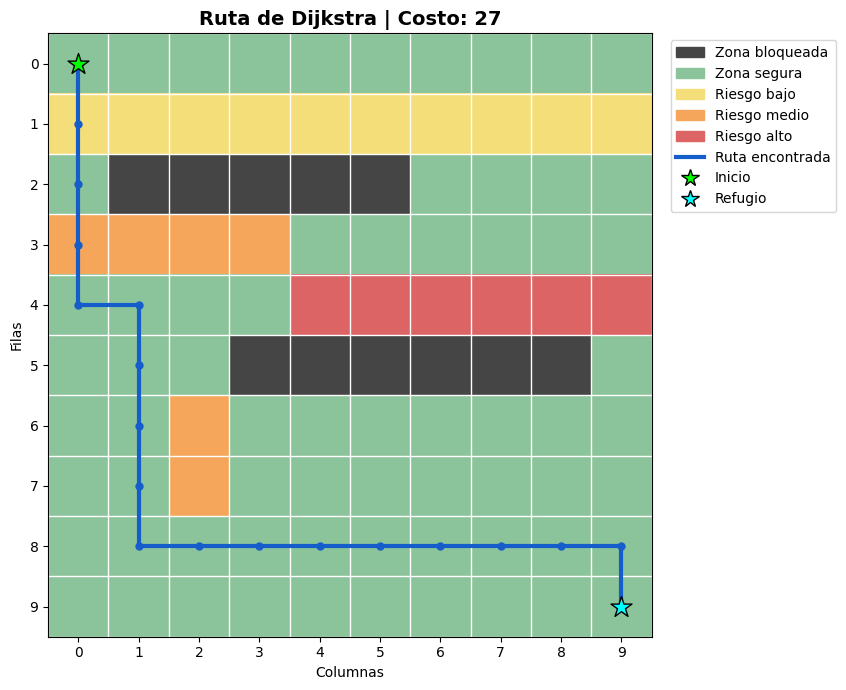


MAPA DE EVACUACIÓN - A*


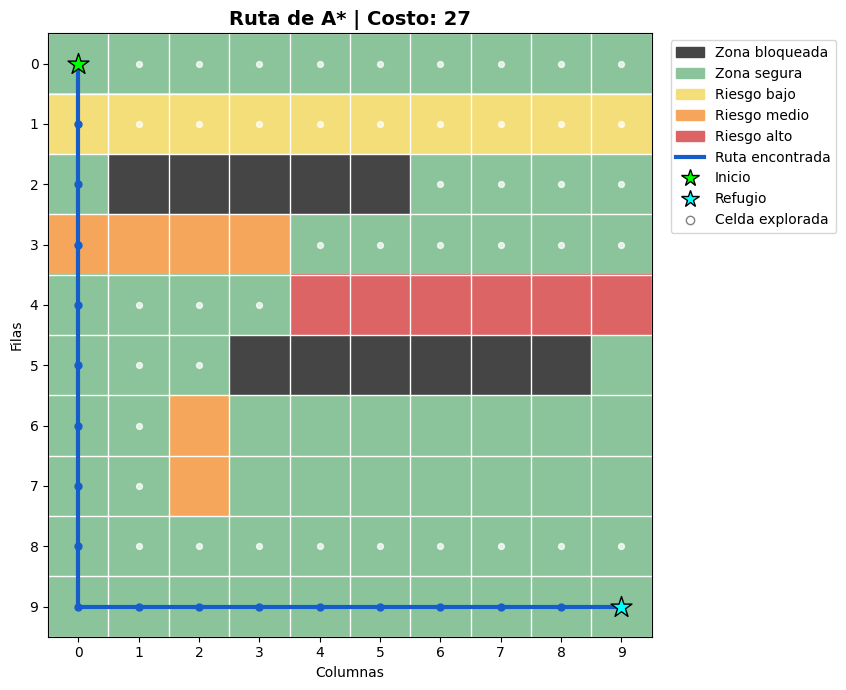


COMPARACIÓN DE ALGORITMOS

DIJKSTRA
Costo total: 27
Pasos: 18

A*
Costo total: 27
Pasos: 18
Nodos expandidos: 63
Nodos generados: 81

Ambos algoritmos encontraron rutas con el mismo costo.


In [21]:


import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from matplotlib.lines import Line2D



def visualizar_terreno(terreno, ruta=None, titulo="Mapa de inundación", explorados=None):

    matriz = terreno.matriz

    # Colores según los niveles de inundación
    colores = [
        "#454545",  # -1: Zona bloqueada
        "#8BC49A",  #  0: Zona segura
        "#F4DE79",  #  1: Riesgo bajo
        "#F5A65B",  #  2: Riesgo medio
        "#DC6464"   #  3: Riesgo alto
    ]

    cmap = ListedColormap(colores)

    norm = BoundaryNorm(
        [-1.5, -0.5, 0.5, 1.5, 2.5, 3.5],
        cmap.N
    )

    # Crear la figura y mostrar el terreno
    fig, ax = plt.subplots(figsize=(9, 7))
    ax.imshow(matriz, cmap=cmap, norm=norm)

    # Mostrar las celdas exploradas por A*
    if explorados is not None and len(explorados) > 0:

        filas = [celda[0] for celda in explorados]
        columnas = [celda[1] for celda in explorados]

        ax.scatter(
            columnas,
            filas,
            color="white",
            s=18,
            alpha=0.75,
            zorder=2
        )

    # Dibujar la ruta encontrada
    if ruta is not None and len(ruta) > 0:

        filas_ruta = [celda[0] for celda in ruta]
        columnas_ruta = [celda[1] for celda in ruta]

        ax.plot(
            columnas_ruta,
            filas_ruta,
            color="#165DCC",
            linewidth=3,
            marker="o",
            markersize=5,
            zorder=3
        )

    # Señalar el inicio
    ax.scatter(
        terreno.inicio[1],
        terreno.inicio[0],
        color="lime",
        marker="*",
        s=250,
        edgecolors="black",
        zorder=5
    )

    # Señalar el refugio
    ax.scatter(
        terreno.refugio[1],
        terreno.refugio[0],
        color="cyan",
        marker="*",
        s=250,
        edgecolors="black",
        zorder=5
    )

    # Configurar cuadrícula
    ax.set_xticks(np.arange(matriz.shape[1]))
    ax.set_yticks(np.arange(matriz.shape[0]))

    ax.set_xticks(
        np.arange(-0.5, matriz.shape[1], 1),
        minor=True
    )

    ax.set_yticks(
        np.arange(-0.5, matriz.shape[0], 1),
        minor=True
    )

    ax.grid(which="minor", color="white", linewidth=1)
    ax.tick_params(which="minor", bottom=False, left=False)

    # Leyenda del mapa
    leyenda = [
        Patch(color="#454545", label="Zona bloqueada"),
        Patch(color="#8BC49A", label="Zona segura"),
        Patch(color="#F4DE79", label="Riesgo bajo"),
        Patch(color="#F5A65B", label="Riesgo medio"),
        Patch(color="#DC6464", label="Riesgo alto"),
        Line2D([0], [0], color="#165DCC",
               linewidth=3, label="Ruta encontrada"),
        Line2D([0], [0], marker="*", color="w",
               markerfacecolor="lime",
               markeredgecolor="black",
               markersize=13, label="Inicio"),
        Line2D([0], [0], marker="*", color="w",
               markerfacecolor="cyan",
               markeredgecolor="black",
               markersize=13, label="Refugio")
    ]

    if explorados is not None:
        leyenda.append(
            Line2D([0], [0], marker="o",
                   linestyle="None",
                   markerfacecolor="white",
                   markeredgecolor="gray",
                   markersize=6,
                   label="Celda explorada")
        )

    ax.legend(
        handles=leyenda,
        bbox_to_anchor=(1.02, 1),
        loc="upper left"
    )

    # Título y nombres de los ejes
    ax.set_title(titulo, fontsize=14, fontweight="bold")
    ax.set_xlabel("Columnas")
    ax.set_ylabel("Filas")

    # Mostrar mensaje cuando no hay ruta
    if ruta is None or len(ruta) == 0:
        ax.text(
            0.5,
            -0.12,
            "No existe una ruta disponible hacia el refugio",
            transform=ax.transAxes,
            ha="center",
            color="red",
            fontsize=11
        )

    plt.tight_layout()
    plt.show()



terreno_visual = TerrenoSimulacion(10, 10)
terreno_visual.configurar_escenario_base()


# Dijkstra
dijkstra_visual = DijkstraEvacuacion(terreno_visual)
ruta_d, costo_d = dijkstra_visual.buscar_ruta()

# A*
a_estrella_visual = AEstrellaEvacuacion(terreno_visual)
ruta_a, costo_a = a_estrella_visual.buscar_ruta()


print("MAPA DE EVACUACIÓN - DIJKSTRA")

visualizar_terreno(
    terreno_visual,
    ruta_d,
    f"Ruta de Dijkstra | Costo: {costo_d}"
)

print("\nMAPA DE EVACUACIÓN - A*")

visualizar_terreno(
    terreno_visual,
    ruta_a,
    f"Ruta de A* | Costo: {costo_a}",
    explorados=a_estrella_visual.explorados
)


print("\n" + "=" * 45)
print("COMPARACIÓN DE ALGORITMOS")
print("=" * 45)

print("\nDIJKSTRA")
print("Costo total:", costo_d)
print("Pasos:", len(ruta_d) - 1 if ruta_d is not None else "Sin ruta")

print("\nA*")
print("Costo total:", costo_a)
print("Pasos:", len(ruta_a) - 1 if ruta_a is not None else "Sin ruta")
print("Nodos expandidos:", a_estrella_visual.nodos_expandidos)
print("Nodos generados:", a_estrella_visual.nodos_generados)

print("\n" + "=" * 45)

if ruta_d is None and ruta_a is None:
    print("Ningún algoritmo encontró una ruta.")

elif ruta_d is None or ruta_a is None:
    print("Los algoritmos obtuvieron resultados diferentes.")

elif costo_d == costo_a:
    print("Ambos algoritmos encontraron rutas con el mismo costo.")

elif costo_d < costo_a:
    print("Dijkstra encontró una ruta de menor costo.")

else:
    print("A* encontró una ruta de menor costo.")


4.2 Visualización de las rutas de Dijkstra y A*

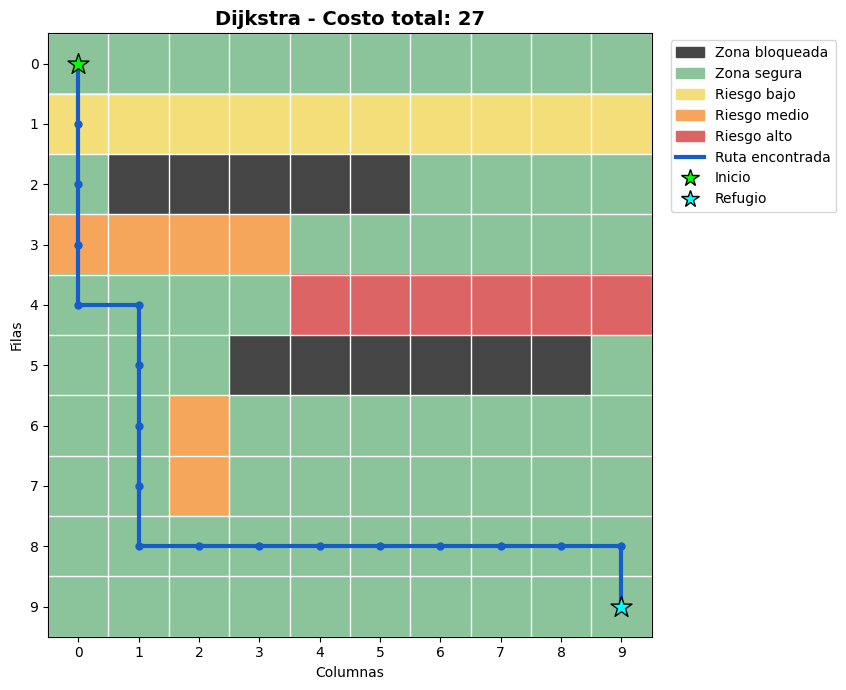

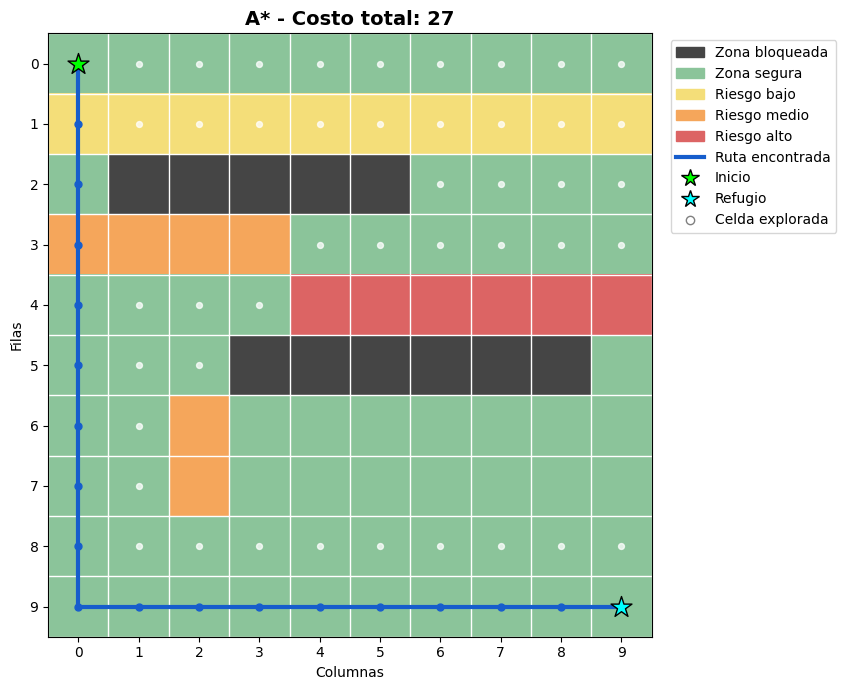

COMPARACIÓN DE RESULTADOS
-------------------------
Dijkstra:
Costo: 27
Pasos: 18

A*:
Costo: 27
Pasos: 18
Nodos expandidos: 63


In [20]:

# Crear el escenario de inundación
terreno_visual = TerrenoSimulacion(10, 10)
terreno_visual.configurar_escenario_base()

# Ejecutar Dijkstra
dijkstra_visual = DijkstraEvacuacion(terreno_visual)
ruta_d, costo_d = dijkstra_visual.buscar_ruta()

# Ejecutar A*
a_estrella_visual = AEstrellaEvacuacion(terreno_visual)
ruta_a, costo_a = a_estrella_visual.buscar_ruta()

# Mostrar mapa con Dijkstra
visualizar_terreno(
    terreno_visual,
    ruta_d,
    f"Dijkstra - Costo total: {costo_d}"
)

# Mostrar mapa con A*
visualizar_terreno(
    terreno_visual,
    ruta_a,
    f"A* - Costo total: {costo_a}",
    explorados=a_estrella_visual.explorados
)

# Mostrar comparación
print("COMPARACIÓN DE RESULTADOS")
print("-------------------------")
print("Dijkstra:")
print("Costo:", costo_d)
print("Pasos:", len(ruta_d) - 1 if ruta_d else "Sin ruta")

print("\nA*:")
print("Costo:", costo_a)
print("Pasos:", len(ruta_a) - 1 if ruta_a else "Sin ruta")
print("Nodos expandidos:", a_estrella_visual.nodos_expandidos)


## **4.3 Interpretación de los resultados**
La representación gráfica permite observar cómo Dijkstra y A* encuentran rutas desde el punto inicial hasta el refugio, considerando las zonas bloqueadas y los diferentes niveles de riesgo de inundación.

Aunque los algoritmos pueden seleccionar recorridos distintos, ambos buscan minimizar el costo acumulado, que incluye la distancia recorrida y la penalización por atravesar zonas inundadas.

En el escenario base se puede comparar el costo total de ambas rutas y observar las celdas exploradas por A*. Estos resultados ayudan a comprender que la mejor ruta no necesariamente es la más corta, sino aquella que presenta el menor costo considerando las condiciones del terreno.

## Sección 5: Pruebas (Asignado a: Integrante 5)